In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # must be set before torch initializes CUDA

import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, free_gpu

## 1. Load & Build Persona Datasets

In [2]:
INCLUDE_COUNTRY = False

VALID_ISSP_QIDS = ["2020:v12", "2020:v6", "2020:v28", "2020:v42"]
VALID_TWIN_QIDS = [f"twin2k:QID9_{i:03d}" for i in range(89, 100)] + ["twin2k:QID41", "twin2k:QID163", "twin2k:QID165"]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS

all_df = pd.concat([load_issp_df(), load_twin2k_df()], ignore_index=True)
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_records = build_persona_dataset(
    all_df[~all_df["qid"].isin(VALID_QIDS)], attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)
valid_grouped = build_eval_set(
    all_df[all_df["qid"].isin(VALID_QIDS)],
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train records : {len(train_records):,}\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

Loaded 1,881,950 records from train_records_resp_minNone_5099daf2.pkl
Loaded 13,183 records from valid_records_minNone_dc60d6c3.pkl
Train records : 1,881,950
Eval sets     : valid=13,183 (3,879 states), grummon=33,798 (3,652 states)


## 2. Configure & Instantiate `GroupedTrainer`


In [3]:
resume = False
seed = 1
val_every = [200, 1000]
save_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b", "4b", or "0.8b"):
PRESET = "9b"

if PRESET == "9b":
    trainer_cfg = dict(
        init_from="runs/kev-9b-resp-issp+twin2k-grouped-newvalid/best",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-newvalid-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        eval_max_questions=200,
        eval_max_chars=100_000,
    )
elif PRESET == "4b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-4b",
        save_dir="runs/kev-4b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=16,
        max_chars_per_group=8_000,
        eval_max_questions=256,
        eval_max_chars=128_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,  # bf16 autocast for eval only; training stays fp32
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    save_every=save_every,
    samples_per_epoch=None,
    seed=seed,
    resume=resume,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

,trainer_config
run_name,kev-9b-resp-issp+twin2k-grouped-newvalid-ep2
save_dir,runs/kev-9b-resp-issp+twin2k-grouped-newvalid-ep2
init_from,runs/kev-9b-resp-issp+twin2k-grouped-newvalid/...
base,Qwen/Qwen3.5-9B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,1
epochs,1
lr_schedule,onecycle


## Run eval

In [6]:
# Test one full evaluation loop across all eval sets with progress bars:
eval_summaries, eval_extra_dfs = trainer.evaluate(show_progress=True)
for s in trainer.eval_sets:
    name = s["name"]
    st = s["last_stats"]
    print(
        f"{name}: {st['n_batches']} batches ({st['n_views_run']:,} states, {st['n_records']:,} records) "
        f"in {st['total_sec']:.2f}s (gpu={st['gpu_sec']:.2f}s)"
    )
    display(eval_summaries[name].to_frame(name=name))

Evaluating valid (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

KeyboardInterrupt: 

## Verify fused weights

In [8]:
# Verify model train mode, weights, module attributes, forward loss, and backward gradients are identical pre/post fused eval:
import importlib
import types
import torch
import data.base as _base_mod
import training.trainer as _trainer_mod
importlib.reload(_base_mod)
importlib.reload(_trainer_mod)
from data.base import fused_eval_context, make_grouped_view

trainer.model.train()
for _, _m in trainer.model.net.lm.named_modules():
    if "forward" in _m.__dict__ and isinstance(_m.__dict__["forward"], types.MethodType) and _m.__dict__["forward"].__func__ is type(_m).forward:
        del _m.__dict__["forward"]
sample_group = trainer._epoch_groups_for(0)[0][:8]
enc, targets = trainer.model.prepare(make_grouped_view(sample_group))

def _sample_loss():
    torch.manual_seed(1234)
    torch.cuda.manual_seed_all(1234)
    with trainer._autocast():
        logits = trainer.model.forward([enc], shared_prefix=True)[0]
    return torch.stack([
        -(q["target"].to(trainer.device) * torch.log_softmax(z.float(), dim=-1)).sum()
        for z, q in zip(logits, targets, strict=True)
    ]).mean()

trainer.model.net.zero_grad(set_to_none=True)
pre_loss = _sample_loss()
pre_loss.backward()
pre_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
pre_loss2 = _sample_loss()
pre_loss2.backward()
pre_grads2 = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
baseline_grad_diff = max((pre_grads[n] - pre_grads2[n]).abs().max().item() for n in pre_grads)
del pre_grads2
pre_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
pre_params = {n: (p.dtype, p.requires_grad, p.detach().clone()) for n, p in trainer.model.net.named_parameters()}

s0 = trainer.eval_sets[0]
b_encs = s0["encs"][:4] if s0["encs"] is not None else [trainer.model.prepare(v)[0] for v in s0["packed_views"][:4]]
trainer.model.eval()
eval_dtype = torch.bfloat16 if trainer.eval_bf16 else None
with torch.no_grad(), trainer._eval_autocast(), fused_eval_context(trainer.model, eval_dtype=eval_dtype):
    trainer.model.net.probs_batch(b_encs, [None] * len(b_encs), [False] * len(b_encs))
trainer.model.train()

post_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
assert pre_dict_keys == post_dict_keys, "Module __dict__ keys changed!"
assert trainer.model.net.graphs is None, "CudaGraphs was not released!"
for n, p in trainer.model.net.named_parameters():
    dt, req_grad, t_pre = pre_params[n]
    assert p.dtype == dt and p.requires_grad == req_grad and torch.equal(p, t_pre), f"Param changed: {n}"

post_loss = _sample_loss()
post_loss.backward()
post_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
free_gpu()

loss_diff = (pre_loss - post_loss).abs().item()
max_grad_diff = max((pre_grads[n] - post_grads[n]).abs().max().item() for n in pre_grads)
print(f"Pre/post fused eval check PASSED | training={trainer.model.training} | loss_diff={loss_diff:.3e} | max_grad_diff={max_grad_diff:.3e} (baseline backward atomicAdd noise={baseline_grad_diff:.3e})")

[W1108 17:40:46.813583255 CUDACachingAllocator.cpp:508] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 62849024, total: 33743044608).
[W1108 17:40:46.820458788 CUDACachingAllocator.cpp:508] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 64946176, total: 33743044608).
[W1108 17:40:46.820506528 CUDACachingAllocator.cpp:508] expandable_segments: memory mapping failed with OOM on device 0 while trying to map 20971520 bytes (free: 64946176, total: 33743044608).


OutOfMemoryError: CUDA out of memory. Tried to allocate 64.00 MiB. GPU 0 has a total capacity of 31.43 GiB of which 61.94 MiB is free. Process 1375 has 78.38 MiB memory in use. Process 1275588 has 1.10 GiB memory in use. Including non-PyTorch memory, this process has 28.93 GiB memory in use. Of the allocated memory 26.55 GiB is allocated by PyTorch, and 9.90 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## Test speed on train step

In [4]:
# Benchmark 1 full optimizer step (12 groups) across (weights_dtype, use_bf16) setups without mutating trainer state:
import random
import time
import numpy as np
import pandas as pd
import torch

macro_batch = trainer._epoch_groups_for(0)[:trainer.effective_groups_bs]
orig_use_bf16 = trainer.use_bf16
orig_trainable = {n: p.detach().clone() for n, p in trainer.model.net.named_parameters() if p.requires_grad}
orig_frozen = [(p, p.data.cpu()) for p in trainer.model.net.parameters() if not p.requires_grad]
rows = []

try:
    if trainer.gradient_checkpointing:
        trainer.model.enable_checkpointing()
    trainer.model.train()

    for label, w_dtype, use_bf16 in [
        ("fp32 weights + fp32 train (TF32)", torch.float32, False),
        ("fp32 weights + bf16 autocast", torch.float32, True),
        ("bf16 weights + bf16 autocast", torch.bfloat16, True),
    ]:
        for p, cpu_t in orig_frozen:
            p.data = cpu_t.to(device=trainer.device, dtype=w_dtype if cpu_t.is_floating_point() else cpu_t.dtype)
        for n, p in trainer.model.net.named_parameters():
            if p.requires_grad:
                p.data.copy_(orig_trainable[n])
        trainer.use_bf16 = use_bf16

        opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=trainer.lr, weight_decay=trainer.weight_decay)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=trainer.lr, total_steps=trainer.total_steps, pct_start=trainer.pct_start)

        # Warmup on 1 group, then reset trainable weights before timing full 12-group step
        trainer.train_one_step(macro_batch[:1], optimizer=opt, scheduler=sched, step=0, total_steps=trainer.total_steps, rng=random.Random(0))
        for n, p in trainer.model.net.named_parameters():
            if p.requires_grad:
                p.data.copy_(orig_trainable[n])
        opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=trainer.lr, weight_decay=trainer.weight_decay)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=trainer.lr, total_steps=trainer.total_steps, pct_start=trainer.pct_start)

        free_gpu()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        step_kls = trainer.train_one_step(macro_batch, optimizer=opt, scheduler=sched, step=0, total_steps=trainer.total_steps, rng=random.Random(0))
        torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        peak_gib = torch.cuda.max_memory_allocated() / (1024 ** 3)
        rows.append({
            "setup": label,
            "step_sec": round(dt, 3),
            "est_epoch_min": round(dt * trainer.steps_per_epoch / 60, 1),
            "peak_vram_gib": round(peak_gib, 2),
            "mean_train_kl": round(float(np.mean(step_kls)), 6),
        })
        del opt, sched
finally:
    trainer.use_bf16 = orig_use_bf16
    for p, cpu_t in orig_frozen:
        p.data = cpu_t.to(device=trainer.device)
    for n, p in trainer.model.net.named_parameters():
        if p.requires_grad:
            p.data.copy_(orig_trainable[n])
            p.grad = None
    free_gpu()

df_bench = pd.DataFrame(rows)
df_bench["speedup_vs_fp32"] = (df_bench["step_sec"].iloc[0] / df_bench["step_sec"]).round(2)
display(df_bench)

,setup,step_sec,est_epoch_min,peak_vram_gib,mean_train_kl,speedup_vs_fp32
0,fp32 weights + fp32 train (TF32),2.709,275.1,22.54,2.426063,1.00
1,fp32 weights + bf16 autocast,2.020,205.2,17.32,2.432151,1.34
2,bf16 weights + bf16 autocast,1.965,199.5,13.79,2.448095,1.38


## Benchmark `(max_questions_per_group, max_chars_per_group)` vs Step Time, Total Time & `val_every` / `save_every`

Measures how `max_questions_per_group` and `max_chars_per_group` trade off:
- **Fewer, larger groups** → more shared-prefix reuse per persona state (`fewer total_steps`, more questions/step, slower `sec_per_step`, higher peak VRAM).
- **More, smaller groups** → less branch padding (`more total_steps`, fewer questions/step, faster `sec_per_step`, lower peak VRAM).
- Converts `sec_per_step` into **total epoch hours**, **minutes between `save_every` / `val_every`**, and **recommended step intervals** for target wall-clock frequencies (without mutating model weights).

In [6]:
import math
import random
import time
import numpy as np
import pandas as pd
import torch
from data.base import group_train_records, release_cuda_graphs

# Candidate (max_questions_per_group, max_chars_per_group) pairs to compare:
GROUPING_GRID = [
    (32, 16_000),
    (48, 24_000),
    (64, 28_000),
    (96, 36_000),
]
N_BENCH_STEPS = 3          # representative 12-group steps to average per setting
TARGET_SAVE_MIN = 15       # target minutes between save_every checkpoints
TARGET_VALID_MIN = 45      # target minutes between valid evaluations
TARGET_GRUMMON_MIN = 180   # target minutes between grummon evaluations

# Estimate single-eval wall time (uses last_stats if already run, else 9B defaults ~64s valid / ~154s grummon)
valid_eval_sec = next((s["last_stats"]["total_sec"] for s in trainer.eval_sets if s["name"] == "valid" and "last_stats" in s), 64.0)
grummon_eval_sec = next((s["last_stats"]["total_sec"] for s in trainer.eval_sets if s["name"] == "grummon" and "last_stats" in s), 154.0)
cur_save_every = trainer.save_every or 50
cur_valid_every = trainer.val_every_by_name["valid"]
cur_grummon_every = trainer.val_every_by_name["grummon"] if "grummon" in trainer.val_every_by_name else cur_valid_every

if trainer.gradient_checkpointing:
    trainer.model.enable_checkpointing()
trainer.model.train()
release_cuda_graphs(trainer.model)

opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=0.0, weight_decay=0.0)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda _: 1.0)
rows = []

try:
    with torch.random.fork_rng(devices=[trainer.device]):
        # 1 warmup micro-batch so CUDA allocator/kernels are warm
        warm_groups = group_train_records(train_records[:5000], max_questions=32, max_chars=16_000, rng=random.Random(0))
        trainer.train_one_step(warm_groups[:trainer.batch_size], optimizer=opt, scheduler=sched, step=0, total_steps=10, rng=random.Random(0))

        for mq, mc in GROUPING_GRID:
            epoch_rng = random.Random(f"{trainer.seed}:epoch:0")
            groups = group_train_records(train_records, max_questions=mq, max_chars=mc, rng=epoch_rng)
            bs = trainer.effective_groups_bs
            n_groups = len(groups)
            steps_per_ep = math.ceil(n_groups / bs)
            mean_q_group = len(train_records) / n_groups
            mean_q_step = mean_q_group * bs

            # Pick N_BENCH_STEPS evenly spaced macro-batches across the epoch
            sample_step_idxs = np.linspace(0, steps_per_ep - 2, N_BENCH_STEPS, dtype=int)
            free_gpu()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

            step_times = []
            status = "OK"
            try:
                for s_idx in sample_step_idxs:
                    macro = groups[s_idx * bs : (s_idx + 1) * bs]
                    torch.cuda.synchronize()
                    t0 = time.perf_counter()
                    trainer.train_one_step(macro, optimizer=opt, scheduler=sched, step=0, total_steps=10, rng=random.Random(int(s_idx)))
                    torch.cuda.synchronize()
                    step_times.append(time.perf_counter() - t0)
            except torch.OutOfMemoryError:
                status = "OOM"

            peak_alloc_gib = torch.cuda.max_memory_allocated() / (1024 ** 3)
            peak_res_gib = torch.cuda.max_memory_reserved() / (1024 ** 3)

            if status == "OK":
                sec_per_step = float(np.mean(step_times))
                q_per_sec = mean_q_step / sec_per_step
                train_hours = (steps_per_ep * sec_per_step) / 3600.0
                n_valid_evals = steps_per_ep // cur_valid_every + 1
                n_grummon_evals = steps_per_ep // cur_grummon_every + 1
                eval_hours = (n_valid_evals * valid_eval_sec + n_grummon_evals * grummon_eval_sec) / 3600.0
                total_hours = train_hours + eval_hours
                cur_save_min = (cur_save_every * sec_per_step) / 60.0
                cur_valid_min = (cur_valid_every * sec_per_step) / 60.0
                cur_grummon_min = (cur_grummon_every * sec_per_step) / 60.0
                rec_save_every = max(10, int(round((TARGET_SAVE_MIN * 60.0 / sec_per_step) / 10.0)) * 10)
                rec_valid_every = max(25, int(round((TARGET_VALID_MIN * 60.0 / sec_per_step) / 25.0)) * 25)
                rec_grummon_every = max(100, int(round((TARGET_GRUMMON_MIN * 60.0 / sec_per_step) / 50.0)) * 50)
            else:
                sec_per_step = q_per_sec = train_hours = eval_hours = total_hours = float("nan")
                cur_save_min = cur_valid_min = cur_grummon_min = float("nan")
                rec_save_every = rec_valid_every = rec_grummon_every = None

            rows.append({
                "max_q": mq,
                "max_chars": mc,
                "status": status,
                "total_steps": steps_per_ep,
                "mean_q/group": round(mean_q_group, 1),
                "mean_q/step": round(mean_q_step, 0),
                "sec/step": round(sec_per_step, 2),
                "q/sec": round(q_per_sec, 1),
                "train_hrs": round(train_hours, 2),
                "total_hrs (w/ eval)": round(total_hours, 2),
                f"min @ save={cur_save_every}": round(cur_save_min, 1),
                f"min @ valid={cur_valid_every}": round(cur_valid_min, 1),
                f"min @ grummon={cur_grummon_every}": round(cur_grummon_min, 1),
                f"rec_save (~{TARGET_SAVE_MIN}m)": rec_save_every,
                f"rec_valid (~{TARGET_VALID_MIN}m)": rec_valid_every,
                f"rec_grummon (~{TARGET_GRUMMON_MIN}m)": rec_grummon_every,
                "peak_alloc_GiB": round(peak_alloc_gib, 2),
                "peak_res_GiB": round(peak_res_gib, 2),
            })
            print(
                f"(mq={mq:3d}, mc={mc:6d}) -> {status} | steps={steps_per_ep:,} | "
                f"{sec_per_step:.2f}s/step ({q_per_sec:.1f} q/s) | train={train_hours:.2f}h | "
                f"peak={peak_alloc_gib:.2f} GiB | rec: save_every={rec_save_every}, val_every=[{rec_valid_every}, {rec_grummon_every}]"
            )
finally:
    opt.zero_grad(set_to_none=True)
    del opt, sched
    for p in trainer.model.trainable_parameters():
        p.grad = None
    free_gpu()

df_grouping_bench = pd.DataFrame(rows)
display(df_grouping_bench)

(mq= 32, mc= 16000) -> OK | steps=6,693 | 16.42s/step (17.1 q/s) | train=30.53h | peak=19.92 GiB | rec: save_every=50, val_every=[175, 650]
(mq= 48, mc= 24000) -> OK | steps=4,888 | 19.75s/step (19.5 q/s) | train=26.81h | peak=21.26 GiB | rec: save_every=50, val_every=[125, 550]
(mq= 64, mc= 28000) -> OK | steps=4,275 | 23.59s/step (18.7 q/s) | train=28.02h | peak=22.07 GiB | rec: save_every=40, val_every=[125, 450]
(mq= 96, mc= 36000) -> OK | steps=3,519 | 30.51s/step (17.5 q/s) | train=29.83h | peak=23.18 GiB | rec: save_every=30, val_every=[100, 350]


,max_q,max_chars,status,total_steps,mean_q/group,mean_q/step,sec/step,q/sec,train_hrs,total_hrs (w/ eval),min @ save=50,min @ valid=200,min @ grummon=1000,rec_save (~15m),rec_valid (~45m),rec_grummon (~180m),peak_alloc_GiB,peak_res_GiB
0,32,16000,OK,6693,23.4,281.0,16.42,17.1,30.53,32.06,13.7,54.7,273.7,50,175,650,19.92,20.45
1,48,24000,OK,4888,32.1,385.0,19.75,19.5,26.81,27.92,16.5,65.8,329.1,50,125,550,21.26,21.87
2,64,28000,OK,4275,36.7,440.0,23.59,18.7,28.02,29.04,19.7,78.6,393.2,40,125,450,22.07,22.60
3,96,36000,OK,3519,44.6,535.0,30.51,17.5,29.83,30.66,25.4,101.7,508.6,30,100,350,23.18,23.79


## Second epoch Train

In [ ]:
resume = True
seed = 1
val_every = [100, 1000]
save_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b", "4b", or "0.8b"):
PRESET = "9b"

if PRESET == "9b":
    trainer_cfg = dict(
        init_from="runs/kev-9b-resp-issp+twin2k-grouped-newvalid/best",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-newvalid-ep2",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=48,
        max_chars_per_group=24000,
        eval_max_questions=200,
        eval_max_chars=100_000,
    )
elif PRESET == "4b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-4b",
        save_dir="runs/kev-4b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=16,
        max_chars_per_group=8_000,
        eval_max_questions=256,
        eval_max_chars=128_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,  # bf16 autocast for eval only; training stays fp32
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    save_every=save_every,
    samples_per_epoch=None,
    seed=seed,
    resume=resume,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

,trainer_config
run_name,kev-9b-resp-issp+twin2k-grouped-newvalid-ep2
save_dir,runs/kev-9b-resp-issp+twin2k-grouped-newvalid-ep2
init_from,runs/kev-9b-resp-issp+twin2k-grouped-newvalid/...
base,Qwen/Qwen3.5-9B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,1
epochs,1
lr_schedule,onecycle


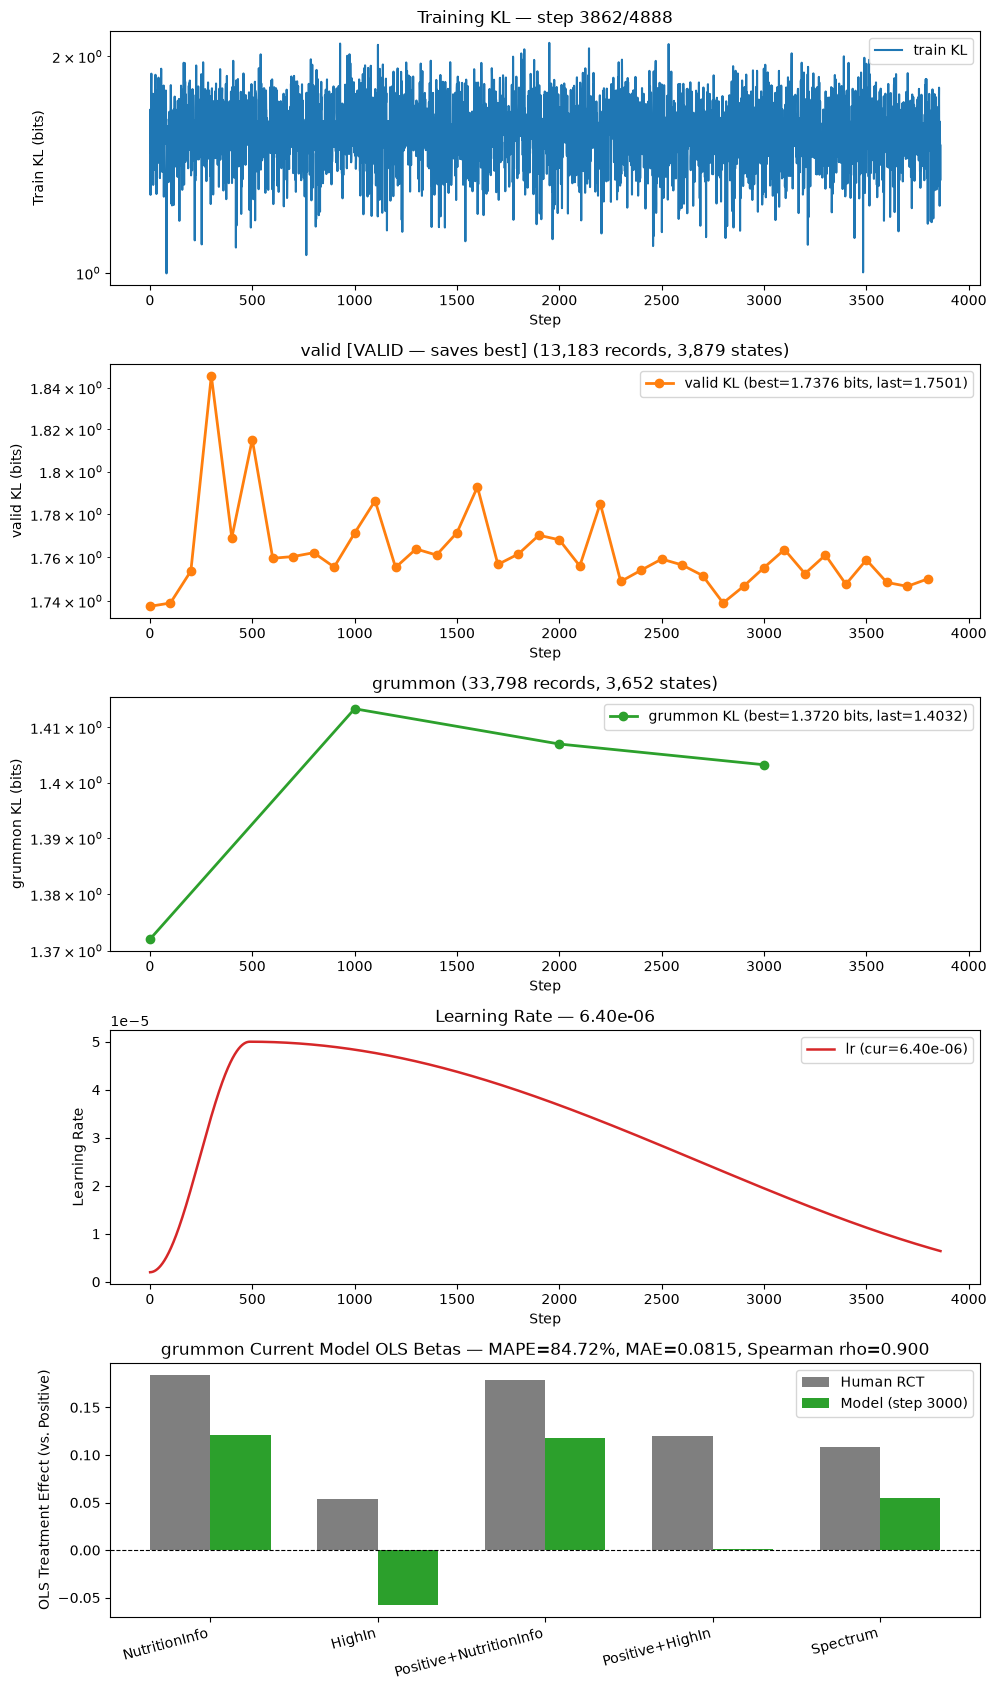

,epoch,step,train_kl,valid_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,1.7376,1.3720,71.30,0.0664,0.0057,0.9000
1,1,100,1.6580,1.7391,—,—,—,—,—
2,1,200,1.5285,1.7537,—,—,—,—,—
3,1,300,1.4631,1.8457,—,—,—,—,—
4,1,400,1.6484,1.7691,—,—,—,—,—
5,1,500,1.4457,1.8151,—,—,—,—,—
6,1,600,1.5382,1.7596,—,—,—,—,—
7,1,700,1.3762,1.7604,—,—,—,—,—
8,1,800,1.6113,1.7622,—,—,—,—,—
9,1,900,1.4960,1.7556,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.1211,0.0633
HighIn,0.0541,-0.0579,0.1120
Positive+NutritionInfo,0.1788,0.1179,0.0609
Positive+HighIn,0.1194,0.0012,0.1183
Spectrum,0.1083,0.0550,0.0533


KeyboardInterrupt: 

In [4]:
plotter = trainer.train()

## 3. Train

`trainer.train()` initializes the composed `TrainingPlotter` display, runs the grouped shared-prefix training loop, saves `best`/`last` checkpoints and lightweight `trainer_state.pt`, and automatically frees optimizer/scheduler/gradient buffers in `finally:`.

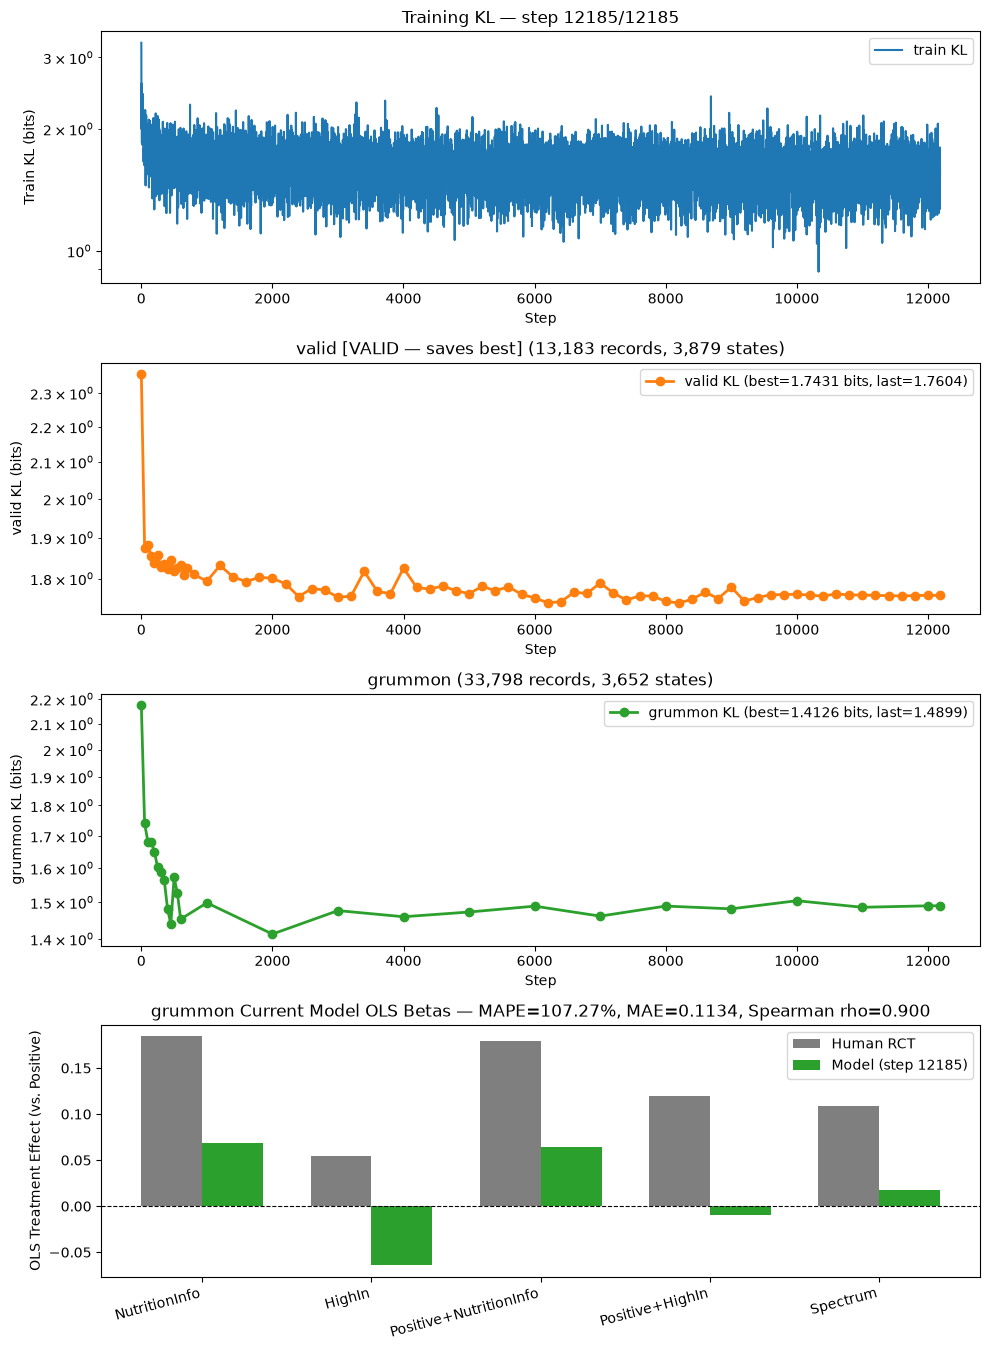

,epoch,step,train_kl,valid_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.3586,2.1745,76.70,0.0636,0.0065,0.8000
1,1,50,1.6237,1.8749,1.7400,83.52,0.0923,0.0089,0.8000
2,1,100,1.8374,1.8825,1.6811,79.38,0.0824,0.0073,0.8000
3,1,150,2.0403,1.8556,1.6818,79.15,0.0812,0.0073,0.8000
4,1,200,1.8008,1.8377,1.6483,81.15,0.0840,0.0077,0.8000
5,1,250,1.7828,1.8580,1.6015,72.68,0.0745,0.0061,0.8000
6,1,300,1.7483,1.8266,1.5888,84.82,0.0840,0.0078,0.8000
7,1,350,1.4940,1.8352,1.5629,86.09,0.0837,0.0077,0.8000
8,1,400,1.8653,1.8220,1.4813,83.89,0.0786,0.0070,0.8000
9,1,450,1.6578,1.8442,1.4394,74.01,0.0725,0.0058,0.8000


,human,model,abs_diff
NutritionInfo,0.1844,0.0689,0.1155
HighIn,0.0541,-0.0642,0.1182
Positive+NutritionInfo,0.1788,0.0647,0.1142
Positive+HighIn,0.1194,-0.0091,0.1285
Spectrum,0.1083,0.0177,0.0906


Resumed kev-4b-resp-issp+twin2k-grouped-newvalid at epoch 1, step 3400/12185 (best_valid_kl=1.7559)


In [5]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [5]:
df_probe = trainer.probe_vram([
    (8, 8_000),
    (16, 8_000),
    (16, 16_000),
    (24, 24_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
mq=  8, mc=  8000 -> OK  | peak_alloc=23.97 GiB (reserved=24.14 GiB) | worst=(8, 104, 200) (1,704 toks) | 1ep_steps=20,576
mq= 16, mc=  8000 -> OK  | peak_alloc=25.12 GiB (reserved=25.45 GiB) | worst=(16, 102, 106) (1,798 toks) | 1ep_steps=12,185


[W1107 18:27:39.217483772 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 125829120 bytes (free: 182845440, total: 33743044608).
[W1107 18:27:39.247403338 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 62914560 bytes (free: 113639424, total: 33743044608).
[W1107 18:27:39.247543828 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 62914560 bytes (free: 113639424, total: 33743044608).


mq= 16, mc= 16000 -> OOM | peak_alloc=28.06 GiB (reserved=28.59 GiB) | worst=(16, 120, 212) (3,512 toks) | 1ep_steps=10,539


,max_questions,max_chars,groups_per_epoch,mean_q_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,8,8000,246907,7.62,20576,20576,"(8, 104, 200)",1704,23.97,24.14,OK
1,16,8000,146213,12.87,12185,12185,"(16, 102, 106)",1798,25.12,25.45,OK
2,16,16000,126462,14.88,10539,10539,"(16, 120, 212)",3512,28.06,28.59,OOM


## Show train records for epoch 1 based on seed 

In [ ]:
import random
from data.base import group_train_records


def epoch1_question_order(seed):
    epoch_rng = random.Random(f"{seed}:epoch:0")
    sampled = (
        epoch_rng.sample(train_records, trainer.n_per_epoch)
        if trainer.samples_per_epoch is not None
        else train_records
    )
    groups = group_train_records(
        sampled,
        max_questions=trainer_cfg["max_questions_per_group"],
        max_chars=trainer_cfg["max_chars_per_group"],
        rng=epoch_rng,
    )
    bs = trainer.effective_groups_bs
    return pd.DataFrame(
        [
            {
                "step": (group_idx // bs) + 1,
                "group_idx": group_idx,
                "n_questions": len(g),
                "persona": g[0]["persona"],
                "qids": [r["qid"] for r in g],
            }
            for group_idx, g in enumerate(groups)
        ]
    )


In [ ]:
SEED_TO_CHECK = 0
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=0 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,62,"Sex=Male, Age=50-64, Education=College graduat...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
1,1,1,47,"Sex=Female, Age=30-49, Education=High school o...","[2024:v23, 2024:v24, 2024:v30, 2024:v26, 2024:..."
2,1,2,1,"Sex=Female, Age=65+, Education=College graduat...",[twin2k:QID57]
3,1,3,35,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID278_5, twin2k:QID277_12, twin2k:QID..."
4,1,4,96,"Sex=Female, Age=18-29, Education=High school o...","[twin2k:QID148, twin2k:QID169, twin2k:QID275, ..."
...,...,...,...,...,...
42214,3518,42214,73,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID233_5, twin2k:QID26_8, twin2k:QID9_..."
42215,3518,42215,75,"Sex=Male, Age=18-29, Education=High school or ...","[twin2k:QID171, twin2k:QID233_3, twin2k:QID9_0..."
42216,3519,42216,54,"Sex=Female, Age=50-64, Education=High school o...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."
42217,3519,42217,54,"Sex=Male, Age=50-64, Education=College graduat...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."


In [ ]:
SEED_TO_CHECK = 1
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=1 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,96,"Sex=Female, Age=30-49, Education=College gradu...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
1,1,1,62,"Sex=Male, Age=65+, Education=College graduate/...","[twin2k:QID245_5, twin2k:QID245_4, twin2k:QID2..."
2,1,2,55,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID150, twin2k:QID236_5, twin2k:QID236..."
3,1,3,62,"Sex=Female, Age=30-49, Education=College gradu...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
4,1,4,21,"Sex=Male, Age=50-64, Education=Associate's deg...","[twin2k:QID29_22, twin2k:QID29_17, twin2k:QID2..."
...,...,...,...,...,...
42214,3518,42214,6,"Sex=Male, Age=30-49, Education=College graduat...","[2017:v22, 2017:v48, 2017:v52, 2017:v50, 2017:..."
42215,3518,42215,56,"Sex=Male, Age=65+, Education=College graduate/...","[2021:v52, 2021:v40, 2021:v42, 2021:v51, 2021:..."
42216,3519,42216,73,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID9_276, twin2k:QID31, twin2k:QID25_4..."
42217,3519,42217,96,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
